# mndsim tutorial: from one motor unit to a virtual trial

This notebook walks through the main ideas of the simulator. It runs top to bottom in about a minute.

> Research and teaching tool. Parameters are illustrative; nothing here predicts the course of a real person.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import mndsim
from mndsim import plotting
from mndsim.phenotypes import TYPICAL

plt.rcParams["figure.dpi"] = 80
pd.set_option("display.precision", 2)
mndsim.__version__

'0.2.0'

## 1. The healthy motor-unit pool

Every region has 120 motor units ordered by size (Henneman's size principle). Small units are recruited first and are slow; large units are fast. Force rises steeply as large units join.

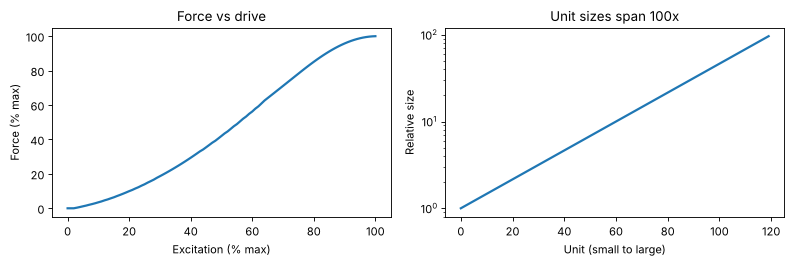

In [2]:
pool = mndsim.MotorUnitPool.from_config()
frac, force = pool.force_excitation_curve()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(frac * 100, force * 100, lw=2)
ax[0].set(xlabel="Excitation (% max)", ylabel="Force (% max)", title="Force vs drive")
ax[1].semilogy(pool.fibers / pool.fibers[0], lw=2)
ax[1].set(xlabel="Unit (small to large)", ylabel="Relative size", title="Unit sizes span 100x")
plt.tight_layout()

## 2. One virtual patient

`simulate` returns trajectories for every region plus clinical read-outs. Time zero is biological disease onset; symptom onset is *emergent*.

In [3]:
res = mndsim.simulate(TYPICAL, months=72)
res.summary().T

,0
patient,typical
onset_region,upper_limb
genotype,sporadic
treatment,untreated
symptom_onset_months,15.73
symptom_region,upper_limb
mu_loss_at_symptom_onset,0.51
cmap_at_symptom_onset,0.71
alsfrs_slope_first_year,-0.75
diagnosis_months,27.73


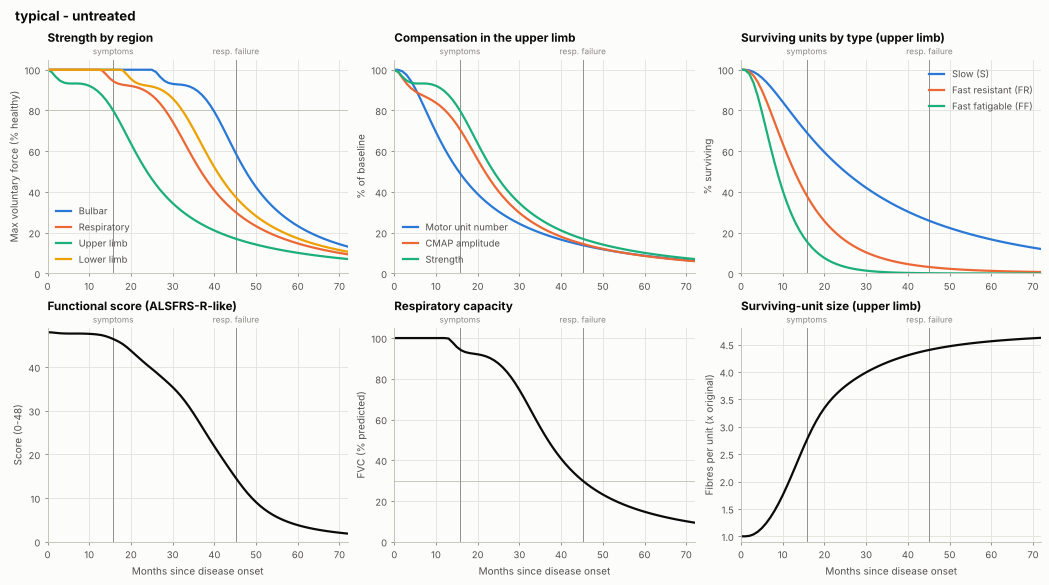

In [4]:
res.plot();

Read the top-middle panel from left to right. **Motor unit number falls first, then CMAP, then strength.** Collateral reinnervation hides the loss, which is why electrophysiology detects disease before weakness does.

## 3. Individual motor-unit fates

In stochastic mode each unit's fate is sampled. Fast-fatigable (FF) units go first; slow (S) units last.

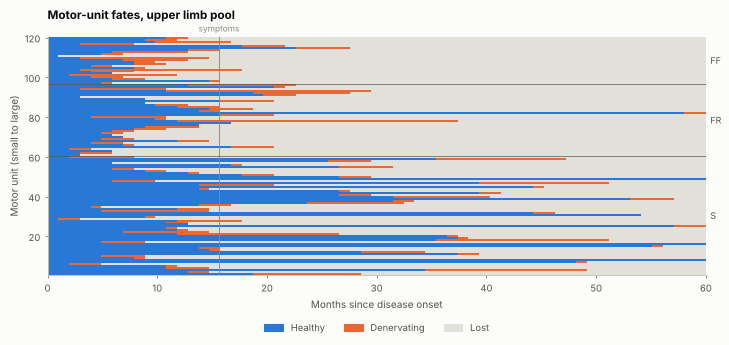

In [5]:
stoch = mndsim.simulate(TYPICAL, months=60, stochastic=True, seed=7, record_units=True)
plotting.plot_motor_units(stoch);

## 4. Phenotypes

In [6]:
batch = mndsim.simulate(list(mndsim.PHENOTYPES.values()), months=200)
batch.summary()[["patient", "onset_region", "symptom_onset_months", "mu_loss_at_symptom_onset",
                 "alsfrs_slope_first_year", "survival_from_symptom_onset"]]

,patient,onset_region,symptom_onset_months,mu_loss_at_symptom_onset,alsfrs_slope_first_year,survival_from_symptom_onset
0,typical,upper_limb,15.73,0.51,-0.75,29.44
1,lower_limb_onset,lower_limb,15.49,0.50,-0.49,47.44
2,bulbar_onset,bulbar,12.17,0.44,-0.80,23.96
3,fast_progressor,upper_limb,6.10,0.26,-1.56,15.86
4,slow_progressor,upper_limb,39.05,0.60,-0.27,70.16
5,umn_dominant,upper_limb,17.45,0.09,-0.24,NaN
6,lmn_dominant,upper_limb,18.25,0.54,-0.72,29.92
7,flail_arm,upper_limb,15.27,0.50,-0.63,57.17
8,sod1_familial,lower_limb,8.98,0.38,-0.74,30.26
9,healthy,upper_limb,NaN,NaN,NaN,NaN


## 5. Counterfactual treatments

The same patient under different mechanisms, all started at diagnosis (12 months after symptom onset).

In [7]:
dx = res.symptom_onset[0] + 12
runs = {"untreated": res}
for name in ["neuroprotective", "anti_excitotoxic", "nmj_stabilizer", "symptomatic"]:
    runs[name] = mndsim.simulate(TYPICAL, mndsim.TREATMENTS[name].at(dx), months=72)
pd.DataFrame({k: {"event (months after symptom onset)": v.event_time[0] - v.symptom_onset[0]} for k, v in runs.items()}).T

,event (months after symptom onset)
untreated,29.44
neuroprotective,37.61
anti_excitotoxic,32.56
nmj_stabilizer,42.21
symptomatic,31.17


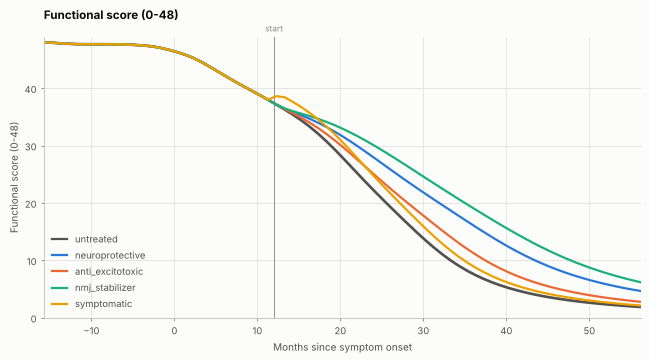

In [8]:
plotting.plot_trajectories(runs, "alsfrs", marks={"start": 12});

Note the **symptomatic** arm: an immediate jump in function, then the same rate of decline. That is the signature that delayed-start trial designs try to detect.

You can also define your own mechanism:

In [9]:
mine = mndsim.Treatment(name="my_compound", umn_protection=0.5, nmj_rescue=0.08, ramp=3)
r = mndsim.simulate(TYPICAL, mine.at(dx), months=72)
print(f"gain: {r.event_time[0] - res.event_time[0]:.1f} months")

gain: 6.2 months


## 6. A virtual cohort

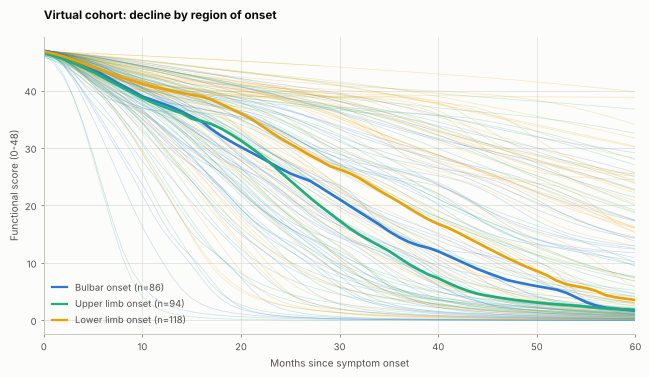

In [10]:
cohort = mndsim.simulate(mndsim.sample_cohort(300, seed=3), months=150, dt=0.5)
plotting.plot_cohort(cohort);

## 7. An in-silico trial

Every eligible patient is simulated both untreated and treated. Replicate trials then resample the pool and test five endpoints. Here we use a small pool and few replicates to keep it fast; use more for real design work.

In [11]:
design = mndsim.TrialDesign(n_per_arm=100, duration=12)
pool = mndsim.build_trial_pool(mndsim.TREATMENTS["neuroprotective"], design, pool_size=600, seed=1)
print(pool)
mndsim.run_trials(pool, n_trials=100, seed=2).power()

TrialPool(600 eligible of 858 screened, treatment: neuroprotective)


,endpoint,power,power_se,median_effect,any_significant
0,alsfrs_slope,0.95,0.02,2.68e-01,0.95
1,survival,0.37,0.05,3.86e-01,0.37
2,cafs,0.93,0.03,2.73e-01,0.93
3,mune_slope,0.29,0.05,6.32e-03,0.29
4,fvc_slope,0.78,0.04,7.34e-01,0.78
5,nfl,0.89,0.03,8.30e-01,0.89


In [12]:
effects = pool.individual_effects()
print(f"events prevented during follow-up: {effects.event_prevented.sum()} of {effects.event_control.notna().sum()}")
effects[["alsfrs_preserved", "event_delay"]].describe()

events prevented during follow-up: 37 of 58


,alsfrs_preserved,event_delay
count,600.00,21.00
mean,3.18,2.32
std,1.88,0.62
min,0.11,0.87
25%,1.60,1.96
50%,3.06,2.29
75%,4.62,2.84
max,8.28,3.20


## 8. A digital twin

Fit a virtual patient to visits (synthetic here) and forecast what-ifs.

In [13]:
visits = pd.read_csv("data/example_patient.csv")
fit = mndsim.fit_patient(visits.months_since_onset, visits.alsfrs, fvc=visits.fvc, onset_region="bulbar")
fit.confidence_intervals()

,parameter,estimate,lower,upper,log_se
0,lmn_rate,0.13,0.10,0.16,0.14
1,spread_rate,0.05,0.05,0.06,0.05


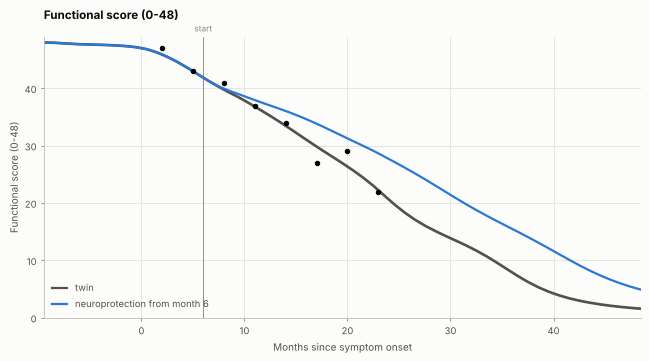

In [14]:
twin = {"twin": fit.simulate(months_after_onset=48),
        "neuroprotection from month 6": fit.counterfactual(mndsim.TREATMENTS["neuroprotective"], 6)}
fig = plotting.plot_trajectories(twin, "alsfrs", marks={"start": 6})
fig.axes[0].scatter(visits.months_since_onset, visits.alsfrs, color="k", s=15, zorder=5);

## 9. What drives what? Global sensitivity analysis

In [15]:
sa = mndsim.global_sensitivity(n_samples=200, seed=0)
sa.prcc.pivot(index="parameter", columns="output", values="prcc")

output,alsfrs_slope_first_year,mu_loss_at_symptom_onset,survival_from_symptom_onset,symptom_onset_months
parameter,,,,
excitotoxicity,-0.55,-0.57,-0.56,-0.80
lmn_rate,-0.93,-0.91,-0.92,-0.97
max_enlargement,0.54,0.98,0.68,0.96
spread_rate,-0.93,-0.02,-0.89,-0.03
sprouting_rate,-0.62,0.79,-0.36,0.69
umn_rate,0.31,0.04,0.22,0.13


Reinnervation capacity (`max_enlargement`) almost entirely decides how many units are lost before symptoms. Spread rate drives survival but not onset.

## 10. The hidden phase and blood NfL

Neurofilament light (NfL) is released by degenerating axons, so it tracks the *rate* of loss, while function tracks the state left after compensation.

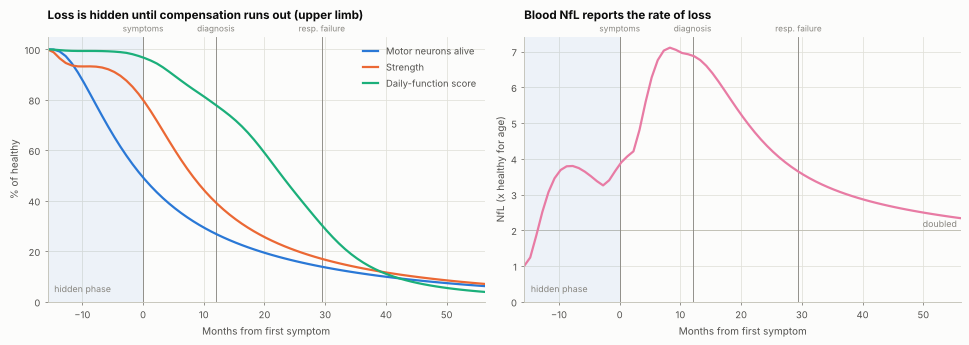

In [16]:
from mndsim import hidden_phase as hp
plotting.plot_hidden_phase(res);

In [17]:
hp.response_lag(TYPICAL, mndsim.TREATMENTS["neuroprotective"])

,start,start_month,nfl_lag,function_lag,max_nfl_reduction,event_gain,symptom_onset_delay
0,presymptomatic (6 mo before symptoms),9.73,5.27,7.27,0.22,15.83,3.2
1,at symptom onset,15.73,4.27,5.27,0.22,14.49,0.0
2,at diagnosis,27.73,5.27,4.27,0.18,8.17,0.0
3,1 year after diagnosis,39.73,4.27,4.27,0.19,1.73,0.0


A disease-modifying drug lowers NfL within months; a symptomatic one never does:

In [18]:
hp.response_lag(TYPICAL, mndsim.TREATMENTS["symptomatic"])[["start", "nfl_lag", "function_lag", "max_nfl_reduction"]]

,start,nfl_lag,function_lag,max_nfl_reduction
0,presymptomatic (6 mo before symptoms),NaN,7.27,0.0
1,at symptom onset,NaN,1.27,0.0
2,at diagnosis,NaN,0.27,0.0
3,1 year after diagnosis,NaN,0.27,0.0


### NfL-triggered treatment in presymptomatic gene carriers

In [19]:
strategies = hp.trigger_strategies(mndsim.TREATMENTS["gene_targeted"], n=200, seed=1)
strategies.summary()

,treated_fraction,median_start_vs_symptoms,median_onset_delay,median_event_gain,median_function_at_+24mo
strategy,,,,,
untreated,0.0,NaN,0.00,0.00,20.63
nfl_trigger,1.0,-2.92,2.02,34.73,39.46
symptom_onset,1.0,0.00,0.00,33.47,38.45
diagnosis,1.0,10.81,0.00,22.93,30.88


See `docs/MODEL.md` for the equations behind all of this.